# Program 9: Implement K-Means Clustering and Evaluate Clustering Quality Using Appropriate Evaluation Metrics Dimensionality Reduction Using Principal Component Analysis (PCA)

**1. Aim**
To implement the K-Means Clustering algorithm using Python and Scikit-learn, and evaluate
the clustering quality using appropriate evaluation metrics such as Silhouette Score, Inertia
(Within-Cluster Sum of Squares), and Davies-Bouldin Index.

**2. Objectives**

After completing this experiment, students will be able to:
• Understand the concept of clustering in machine learning.
• Learn the working principle of the K-Means clustering algorithm.
• Apply K-Means to group similar data points.
• Determine the optimal number of clusters.
• Visualize clustered data.
• Evaluate clustering quality using standard evaluation metrics.
• Interpret clustering results for real-world applications.

# Introduction to Clustering

Clustering is an Unsupervised Machine Learning technique used to group similar data points
into clusters without using predefined class labels.
Unlike supervised learning, clustering works with unlabeled data.
The goal is to ensure that:
• Objects within the same cluster are highly similar.
• Objects in different clusters are significantly different.
Examples:
• Customer Segmentation
• Image Segmentation
• Document Clustering
• Market Basket Analysis
• Disease Pattern Analysis

3.2 What is K-Means Clustering?
K-Means Clustering is one of the most widely used unsupervised learning algorithms for
partitioning a dataset into K clusters, where each data point belongs to the cluster with the
nearest centroid.
A centroid is the mean (average) position of all data points in a cluster.

3.3 Working of K-Means Algorithm
The K-Means algorithm follows these steps:
1. Choose the number of clusters (K).
2. Randomly initialize K centroids.
3. Calculate the distance between each data point and the centroids.
4. Assign each data point to the nearest centroid.
5. Recalculate the centroid of each cluster.
6. Repeat Steps 3–5 until the centroids no longer change significantly or the maximum
number of iterations is reached.

3.4 Distance Measure
K-Means generally uses the Euclidean Distance to measure similarity.
[
d=\sqrt{\sum_{i=1}^{n}(x_i-y_i)^2}
]
Where:
• (x_i) = Feature value of the first point
• (y_i) = Feature value of the second point
A smaller distance indicates greater similarity.

3.5 Choosing the Value of K
Selecting the correct value of K is important for meaningful clustering.
Elbow Method
The Elbow Method plots the Within-Cluster Sum of Squares (WCSS) or Inertia against
different values of K.
The optimal value of K is usually found at the elbow point, where the decrease in inertia begins
to slow down.
Example:

WCSS
^
|\
| \
| \
| \
| \__
| \__
+---------------------> K
↑
Optimal K

3.6 Evaluation Metrics
Since clustering does not have predefined labels, different evaluation metrics are used.
1. Inertia (Within-Cluster Sum of Squares)
Inertia measures the sum of squared distances between each data point and its assigned cluster
centroid.
• Lower inertia indicates more compact clusters.
• However, inertia always decreases as K increases, so it should not be used alone.

2. Silhouette Score
The Silhouette Score measures how similar an object is to its own cluster compared to other
clusters.
The score ranges from -1 to 1.
Interpretation:
• 1 → Excellent clustering.
• 0 → Overlapping clusters.
• -1 → Incorrect clustering.
Higher values indicate better-defined clusters.

3. Davies-Bouldin Index (DBI)
The Davies-Bouldin Index measures the average similarity between clusters.

Interpretation:
• Lower DBI values indicate better clustering.
• A DBI of 0 represents perfectly separated clusters.

3.7 Applications of K-Means Clustering
• Customer Segmentation
• Market Basket Analysis
• Image Compression
• Document Classification
• Social Network Analysis
• Recommendation Systems
• Fraud Detection
• Healthcare Analytics
• Gene Expression Analysis
• Geographic Data Analysis

Original Dataset
   CustomerID  AnnualIncome  SpendingScore
0           1            15             39
1           2            16             81
2           3            17              6
3           4            18             77
4           5            19             40
5           6            20             76
6           7            21              6
7           8            22             94
8           9            23              3
9          10            24             72

Clustered Dataset
   CustomerID  AnnualIncome  SpendingScore  Cluster
0           1            15             39        0
1           2            16             81        0
2           3            17              6        1
3           4            18             77        0
4           5            19             40        1
5           6            20             76        2
6           7            21              6        1
7           8            22             94        2
8           9          

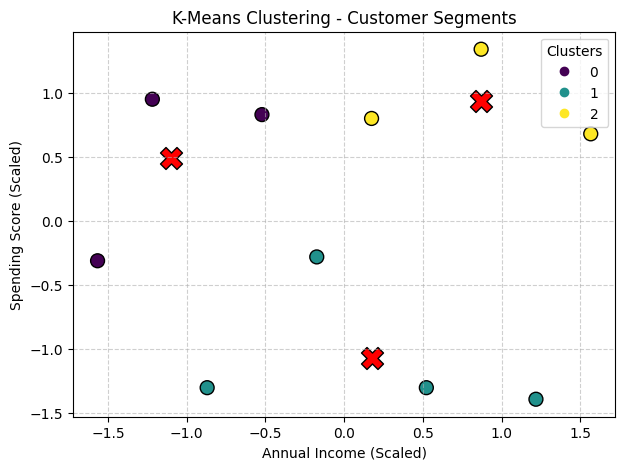

In [6]:
import io
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

# -----------------------------
# Embedded Dataset
# -----------------------------
csv_data = """CustomerID,AnnualIncome,SpendingScore
1,15,39
2,16,81
3,17,6
4,18,77
5,19,40
6,20,76
7,21,6
8,22,94
9,23,3
10,24,72"""

# Read dataset directly from the string variable
df = pd.read_csv(io.StringIO(csv_data))

print("Original Dataset")
print(df)

# -----------------------------
# Feature Selection
# -----------------------------
X = df[["AnnualIncome", "SpendingScore"]]

# -----------------------------
# Feature Scaling
# -----------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# -----------------------------
# Apply K-Means
# -----------------------------
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Add cluster labels to original DataFrame
df["Cluster"] = clusters

print("\nClustered Dataset")
print(df)

# -----------------------------
# Evaluation Metrics
# -----------------------------
print("\nInertia:", kmeans.inertia_)

sil_score = silhouette_score(X_scaled, clusters)
print("Silhouette Score:", sil_score)

db_index = davies_bouldin_score(X_scaled, clusters)
print("Davies-Bouldin Index:", db_index)

# -----------------------------
# Visualization
# -----------------------------
plt.figure(figsize=(7, 5))

# Plot the customer data points color-coded by their cluster
scatter = plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap="viridis",
    s=100,
    edgecolors="k",
)

# Plot the cluster centers (Centroids)
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    s=250,
    color="red",
    edgecolors="black",
    label="Centroids",
)

plt.title("K-Means Clustering - Customer Segments")
plt.xlabel("Annual Income (Scaled)")
plt.ylabel("Spending Score (Scaled)")
plt.legend(*scatter.legend_elements(), title="Clusters", loc="upper right")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

**Result**

The K-Means clustering algorithm was successfully implemented to group customers based on
Annual Income and Spending Score. The dataset was standardized before clustering, and the
clustering quality was evaluated using Inertia, Silhouette Score, and Davies-Bouldin Index.
The visualization clearly showed distinct customer groups and their corresponding cluster
centroids.